# 08 · DL evaluation: MLP vs XGBoost vs hybrid (Phase 2)

In [1]:
# 1. Imports and project setup

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

SEED = 42
N_BOOTSTRAPS = 2000

np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "results"
DL_RESULTS = RESULTS / "dl"

DL_RESULTS.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Results directory:", DL_RESULTS)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Project root: /Users/prathapanianusha/water-quality-prediction
Results directory: /Users/prathapanianusha/water-quality-prediction/results/dl
NumPy: 2.5.4
Pandas: 3.0.6


In [2]:
# 2. Inspect saved prediction files

files_to_inspect = {
    "XGBoost validation": RESULTS / "validation_predictions.csv",
    "MLP validation": DL_RESULTS / "predictions_mlp_val.csv",
    "Hybrid validation": RESULTS / "hybrid_val_preds.csv",
    "MLP test": DL_RESULTS / "predictions_mlp.csv",
    "Hybrid test": RESULTS / "predictions_hybrid.csv",
}

for name, path in files_to_inspect.items():
    print(f"\n{name}")
    print("File exists:", path.exists())

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))


XGBoost validation
File exists: True
Shape: (104216, 5)
Columns: ['row_id', 'model', 'y_true', 'y_pred', 'split']


,row_id,model,y_true,y_pred,split
0,2183,DummyRegressor,93.1447,90.35869,val
1,77,DummyRegressor,92.8425,90.35869,val
2,81,DummyRegressor,100.0000,90.35869,val



MLP validation
File exists: True
Shape: (26054, 3)
Columns: ['row_id', 'y_true', 'y_pred']


,row_id,y_true,y_pred
0,2183,93.1447,84.969475
1,77,92.8425,89.438194
2,81,100.0000,89.219010



Hybrid validation
File exists: True
Shape: (26054, 6)
Columns: ['row_id', 'y_true', 'xgb_pred', 'y_true_mlp', 'mlp_pred', 'blend_pred']


,row_id,y_true,xgb_pred,y_true_mlp,mlp_pred,blend_pred
0,2183,93.1447,88.34547,93.1447,84.969475,86.826272
1,77,92.8425,86.00266,92.8425,89.438194,87.548651
2,81,100.0000,90.93162,100.0000,89.219010,90.160945



MLP test
File exists: True
Shape: (51973, 3)
Columns: ['row_id', 'y_true', 'y_pred']


,row_id,y_true,y_pred
0,2114,100.0000,82.291794
1,330,93.1167,89.924040
2,2550,93.1167,89.924040



Hybrid test
File exists: True
Shape: (51973, 2)
Columns: ['row_id', 'y_pred']


,row_id,y_pred
0,2114,84.891514
1,330,90.618063
2,2550,90.618063


In [3]:
# 3. Identify the XGBoost validation predictions

xgb_all = pd.read_csv(RESULTS / "validation_predictions.csv")

print("Models available in validation file:")
display(
    xgb_all.groupby("model").agg(
        rows=("row_id", "count"),
        unique_rows=("row_id", "nunique"),
        mean_prediction=("y_pred", "mean"),
    ).sort_values("rows", ascending=False)
)

Models available in validation file:


,rows,unique_rows,mean_prediction
model,,,
DummyRegressor,26054,26054,90.358690
RandomForestRegressor,26054,26054,89.488048
Ridge,26054,26054,89.529198
XGBRegressor,26054,26054,89.571355


In [4]:
# 4. Align XGBoost, MLP and hybrid validation predictions

xgb_model_names = [
    name for name in xgb_all["model"].unique()
    if "xgb" in str(name).lower()
]

print("XGBoost model candidates:", xgb_model_names)

assert len(xgb_model_names) == 1, (
    "Expected exactly one XGBoost model. "
    "Check the model names printed above."
)

xgb_val = (
    xgb_all[
        (xgb_all["model"] == xgb_model_names[0])
        & (xgb_all["split"] == "val")
    ][["row_id", "y_true", "y_pred"]]
    .rename(columns={"y_pred": "xgb_pred"})
)

mlp_val = (
    pd.read_csv(DL_RESULTS / "predictions_mlp_val.csv")
    .rename(columns={"y_pred": "mlp_pred"})
)

hybrid_val = pd.read_csv(RESULTS / "hybrid_val_preds.csv")

# Verify each prediction file has unique row IDs
assert xgb_val["row_id"].is_unique
assert mlp_val["row_id"].is_unique
assert hybrid_val["row_id"].is_unique

# Merge using row IDs, not file order
comparison = (
    xgb_val
    .merge(
        mlp_val[["row_id", "y_true", "mlp_pred"]],
        on="row_id",
        validate="one_to_one",
        suffixes=("_xgb", "_mlp"),
    )
    .merge(
        hybrid_val[["row_id", "blend_pred"]],
        on="row_id",
        validate="one_to_one",
    )
)

# Verify that actual targets agree
assert np.allclose(comparison["y_true_xgb"], comparison["y_true_mlp"])
assert len(comparison) == 26054

comparison = comparison.rename(
    columns={"y_true_xgb": "y_true"}
)

print("Validation alignment successful.")
print("Rows:", len(comparison))
print("Columns:", comparison.columns.tolist())
display(comparison.head())

XGBoost model candidates: ['XGBRegressor']
Validation alignment successful.
Rows: 26054
Columns: ['row_id', 'y_true', 'xgb_pred', 'y_true_mlp', 'mlp_pred', 'blend_pred']


,row_id,y_true,xgb_pred,y_true_mlp,mlp_pred,blend_pred
0,2183,93.1447,88.842758,93.1447,84.969475,86.826272
1,77,92.8425,88.155945,92.8425,89.438194,87.548651
2,81,100.0000,91.390663,100.0000,89.219010,90.160945
3,110,78.8125,89.729584,78.8125,88.387794,89.078661
4,211,76.7313,85.283630,76.7313,87.838830,86.610275


In [5]:
# 5. Calculate validation metrics for all three models

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


y_true = comparison["y_true"].to_numpy()

validation_results = []

models = {
    "XGBoost": comparison["xgb_pred"].to_numpy(),
    "MLP": comparison["mlp_pred"].to_numpy(),
    "Hybrid": comparison["blend_pred"].to_numpy()
}

for model_name, predictions in models.items():
    metrics = calculate_metrics(y_true, predictions)

    validation_results.append({
        "Model": model_name,
        **metrics
    })

validation_metrics = pd.DataFrame(validation_results)

print("VALIDATION PERFORMANCE COMPARISON")
display(validation_metrics.round(4))

# Save validation metrics
validation_metrics.to_csv(
    DL_RESULTS / "validation_metrics.csv",
    index=False
)

print("Saved validation metrics successfully.")

VALIDATION PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2
0,XGBoost,7.7292,11.2048,0.3478
1,MLP,7.7673,11.2311,0.3447
2,Hybrid,7.6759,11.1414,0.3552


Saved validation metrics successfully.


In [6]:
# 6. Station-level bootstrap confidence intervals

from src.ablations import station_bootstrap_ci
import inspect

print(inspect.signature(station_bootstrap_ci))

(df: 'pd.DataFrame', group_col: 'str' = 'site_id', y_true_col: 'str' = 'y_true', y_pred_col: 'str' = 'y_pred', metric: 'str' = 'mae', n_boot: 'int' = 2000, seed: 'int' = 42, alpha: 'float' = 0.05) -> 'Tuple[float, float, float]'


In [9]:
# 7. Recover station IDs for validation rows

dataset = pd.read_csv(ROOT / "data/processed/final_dataset.csv")

# Recreate the original station-based validation split
val_df = dataset[dataset["split"] == "val"].copy()

print("Validation rows in dataset:", len(val_df))
print("Validation prediction rows:", len(comparison))

# Check whether the original validation ordering matches prediction row IDs
assert len(val_df) == len(comparison), "Validation row counts do not match!"

# Recover station IDs using the original row order
station_lookup = val_df[["site_id"]].reset_index(drop=True).copy()

# Attach station IDs to the aligned predictions
bootstrap_df = comparison.reset_index(drop=True).copy()
bootstrap_df["site_id"] = station_lookup["site_id"]

# Verify the mapping
assert bootstrap_df["site_id"].notna().all()
assert len(bootstrap_df) == 26054

print("\nStation mapping successful!")
print("Unique validation stations:", bootstrap_df["site_id"].nunique())
display(bootstrap_df.head())

Validation rows in dataset: 26054
Validation prediction rows: 26054

Station mapping successful!
Unique validation stations: 1136


,row_id,y_true,xgb_pred,y_true_mlp,mlp_pred,blend_pred,site_id
0,2183,93.1447,88.842758,93.1447,84.969475,86.826272,Canada|SE728744-162653
1,77,92.8425,88.155945,92.8425,89.438194,87.548651,Canada|FRHR03105500
2,81,100.0000,91.390663,100.0000,89.219010,90.160945,Canada|NL92_KETMWT
3,110,78.8125,89.729584,78.8125,88.387794,89.078661,Canada|SE643167-140119
4,211,76.7313,85.283630,76.7313,87.838830,86.610275,Canada|LVV0270200


In [11]:
# 8. Map prediction row IDs to original dataset rows

dataset = pd.read_csv(ROOT / "data/processed/final_dataset.csv")

# Use the original DataFrame index as the row identifier
dataset.index.name = "row_id"

station_lookup = (
    dataset[["site_id", "target_ccme_value"]]
    .reset_index()
)

# Match each prediction to its original dataset row
bootstrap_df = comparison.merge(
    station_lookup[["row_id", "site_id", "target_ccme_value"]],
    on="row_id",
    how="left",
    validate="one_to_one"
)

# Verify station and target alignment
assert bootstrap_df["site_id"].notna().all()
assert np.allclose(
    bootstrap_df["y_true"],
    bootstrap_df["target_ccme_value"]
), "Target values do not match!"

assert len(bootstrap_df) == len(comparison)

print("Correct row mapping verified!")
print("Validation rows:", len(bootstrap_df))
print("Unique stations:", bootstrap_df["site_id"].nunique())

display(
    bootstrap_df[
        ["row_id", "site_id", "y_true", "target_ccme_value"]
    ].head(10)
)

Correct row mapping verified!
Validation rows: 26054
Unique stations: 1136


,row_id,site_id,y_true,target_ccme_value
0,2183,Canada|AL048,93.1447,93.1447
1,77,Canada|BAB7,92.8425,92.8425
2,81,Canada|BASAN_4-20,100.0000,100.0000
3,110,Canada|BERW_00360,78.8125,78.8125
4,211,Canada|BERW_00360,76.7313,76.7313
5,85,Canada|BERW_01281,100.0000,100.0000
6,2501,Canada|BERW_01281,100.0000,100.0000
7,87,Canada|BERW_01281,87.1756,87.1756
8,2503,Canada|BERW_01281,100.0000,100.0000
9,88,Canada|BERW_01281,62.6814,62.6814


In [12]:
# 9. Calculate 95% station-bootstrap confidence intervals

from src.ablations import station_bootstrap_ci

bootstrap_results = []

model_columns = {
    "XGBoost": "xgb_pred",
    "MLP": "mlp_pred",
    "Hybrid": "blend_pred"
}

for model_name, prediction_col in model_columns.items():

    # MAE confidence interval
    mae_result = station_bootstrap_ci(
        bootstrap_df,
        group_col="site_id",
        y_true_col="y_true",
        y_pred_col=prediction_col,
        metric="mae",
        n_boot=N_BOOTSTRAPS,
        seed=SEED
    )

    # RMSE confidence interval
    rmse_result = station_bootstrap_ci(
        bootstrap_df,
        group_col="site_id",
        y_true_col="y_true",
        y_pred_col=prediction_col,
        metric="rmse",
        n_boot=N_BOOTSTRAPS,
        seed=SEED
    )

    bootstrap_results.append({
        "Model": model_name,
        "MAE": mae_result[0],
        "MAE_CI_Lower": mae_result[1],
        "MAE_CI_Upper": mae_result[2],
        "RMSE": rmse_result[0],
        "RMSE_CI_Lower": rmse_result[1],
        "RMSE_CI_Upper": rmse_result[2]
    })

bootstrap_ci_df = pd.DataFrame(bootstrap_results)

bootstrap_ci_df.to_csv(
    DL_RESULTS / "station_bootstrap_ci.csv",
    index=False
)

display(bootstrap_ci_df.round(4))

print("Saved: results/dl/station_bootstrap_ci.csv")

,Model,MAE,MAE_CI_Lower,MAE_CI_Upper,RMSE,RMSE_CI_Lower,RMSE_CI_Upper
0,XGBoost,7.7292,7.0941,8.4458,11.2048,10.3419,12.1641
1,MLP,7.7673,7.1183,8.5026,11.2311,10.3740,12.2159
2,Hybrid,7.6759,7.0311,8.4033,11.1414,10.2860,12.1036


Saved: results/dl/station_bootstrap_ci.csv


In [13]:
# 10. Paired station-bootstrap RMSE differences vs XGBoost

rng = np.random.default_rng(SEED)

station_groups = {
    station: group
    for station, group in bootstrap_df.groupby("site_id")
}

station_ids = np.array(list(station_groups.keys()))

def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

paired_results = []

for model_name, prediction_col in {
    "MLP": "mlp_pred",
    "Hybrid": "blend_pred"
}.items():

    differences = []

    for _ in range(N_BOOTSTRAPS):

        sampled_stations = rng.choice(
            station_ids,
            size=len(station_ids),
            replace=True
        )

        sampled_parts = [
            station_groups[station]
            for station in sampled_stations
        ]

        sample = pd.concat(sampled_parts, ignore_index=True)

        y = sample["y_true"].to_numpy()

        xgb_rmse = calculate_rmse(
            y,
            sample["xgb_pred"].to_numpy()
        )

        model_rmse = calculate_rmse(
            y,
            sample[prediction_col].to_numpy()
        )

        differences.append(model_rmse - xgb_rmse)

    differences = np.array(differences)

    paired_results.append({
        "Model": model_name,
        "Mean_RMSE_Difference": differences.mean(),
        "CI_Lower": np.percentile(differences, 2.5),
        "CI_Upper": np.percentile(differences, 97.5)
    })

paired_rmse_df = pd.DataFrame(paired_results)

paired_rmse_df.to_csv(
    DL_RESULTS / "paired_rmse_differences.csv",
    index=False
)

display(paired_rmse_df.round(4))

print("Saved: results/dl/paired_rmse_differences.csv")

,Model,Mean_RMSE_Difference,CI_Lower,CI_Upper
0,MLP,0.0286,-0.0946,0.1436
1,Hybrid,-0.0618,-0.1185,-0.0094


Saved: results/dl/paired_rmse_differences.csv


In [14]:
# 11. Country-level and CCME score-band error analysis

# Recover country and original CCME class using row_id
metadata = (
    dataset[["country", "target_ccme_class"]]
    .reset_index()
    .rename(columns={"index": "row_id"})
)

error_df = bootstrap_df.merge(
    metadata,
    on="row_id",
    how="left",
    validate="one_to_one"
)

assert error_df["country"].notna().all()
assert error_df["target_ccme_class"].notna().all()

# Calculate prediction errors
prediction_columns = {
    "XGBoost": "xgb_pred",
    "MLP": "mlp_pred",
    "Hybrid": "blend_pred"
}

for model_name, pred_col in prediction_columns.items():
    error_df[f"{model_name}_error"] = (
        error_df[pred_col] - error_df["y_true"]
    )
    error_df[f"{model_name}_abs_error"] = (
        error_df[f"{model_name}_error"].abs()
    )

# Helper for grouped error metrics
def grouped_error_metrics(data, group_column):
    records = []

    for group_value, group in data.groupby(group_column):
        for model_name in prediction_columns:
            errors = group[f"{model_name}_error"].to_numpy()

            records.append({
                group_column: group_value,
                "Model": model_name,
                "Rows": len(group),
                "MAE": np.mean(np.abs(errors)),
                "RMSE": np.sqrt(np.mean(errors ** 2)),
                "Mean_Error": np.mean(errors)
            })

    return pd.DataFrame(records)

# Country-level analysis
country_errors = grouped_error_metrics(error_df, "country")

country_errors.to_csv(
    DL_RESULTS / "country_error_analysis.csv",
    index=False
)

# CCME score-band analysis
ccme_errors = grouped_error_metrics(
    error_df,
    "target_ccme_class"
)

ccme_errors.to_csv(
    DL_RESULTS / "ccme_band_error_analysis.csv",
    index=False
)

print("COUNTRY-LEVEL ERROR ANALYSIS")
display(country_errors.round(4))

print("\nCCME SCORE-BAND ERROR ANALYSIS")
display(ccme_errors.round(4))

print("\nSaved:")
print("results/dl/country_error_analysis.csv")
print("results/dl/ccme_band_error_analysis.csv")

COUNTRY-LEVEL ERROR ANALYSIS


,country,Model,Rows,MAE,RMSE,Mean_Error
0,Canada,XGBoost,314,7.1041,10.0292,-0.4550
1,Canada,MLP,314,7.3977,10.2402,-1.3106
2,Canada,Hybrid,314,7.1368,9.9566,-0.8826
3,England,XGBoost,19396,9.1845,12.4745,0.4219
4,England,MLP,19396,9.2065,12.5124,0.5449
5,England,Hybrid,19396,9.1221,12.4145,0.4828
6,Ireland,XGBoost,5986,3.3749,6.0140,-0.2730
7,Ireland,MLP,5986,3.4488,5.9501,-0.2781
8,Ireland,Hybrid,5986,3.3558,5.9153,-0.2742
9,USA,XGBoost,358,2.2390,3.6176,-0.7745



CCME SCORE-BAND ERROR ANALYSIS


,target_ccme_class,Model,Rows,MAE,RMSE,Mean_Error
0,Excellent,XGBoost,10608,5.8217,8.0895,-5.7846
1,Excellent,MLP,10608,5.9198,8.0880,-5.8943
2,Excellent,Hybrid,10608,5.8375,8.0230,-5.8375
3,Fair,XGBoost,2272,10.6655,12.3628,10.2323
4,Fair,MLP,2272,11.0900,12.7111,10.4608
5,Fair,Hybrid,2272,10.7636,12.3993,10.3228
6,Good,XGBoost,10926,5.0519,6.3028,-1.4580
7,Good,MLP,10926,4.9930,6.3294,-1.1774
8,Good,Hybrid,10926,4.9103,6.1667,-1.3150
9,Marginal,XGBoost,1928,25.2892,26.6568,25.2796



Saved:
results/dl/country_error_analysis.csv
results/dl/ccme_band_error_analysis.csv


In [15]:
# 12. Focused analysis of polluted water predictions

polluted_df = error_df[
    error_df["y_true"] < 60
].copy()

print("Polluted validation observations:", len(polluted_df))
print(
    "Percentage of validation data:",
    round(100 * len(polluted_df) / len(error_df), 2),
    "%"
)

polluted_results = []

for model_name, pred_col in prediction_columns.items():

    errors = polluted_df[pred_col] - polluted_df["y_true"]

    polluted_results.append({
        "Model": model_name,
        "Rows": len(polluted_df),
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Mean_Error": np.mean(errors),
        "Overprediction_Rate": 100 * np.mean(errors > 0),
        "Mean_Prediction": polluted_df[pred_col].mean(),
        "Mean_Actual": polluted_df["y_true"].mean()
    })

polluted_results_df = pd.DataFrame(polluted_results)

polluted_results_df.to_csv(
    DL_RESULTS / "polluted_water_error_analysis.csv",
    index=False
)

display(polluted_results_df.round(4))

print("Saved: results/dl/polluted_water_error_analysis.csv")

Polluted validation observations: 1755
Percentage of validation data: 6.74 %


,Model,Rows,MAE,RMSE,Mean_Error,Overprediction_Rate,Mean_Prediction,Mean_Actual
0,XGBoost,1755,29.1240,30.2208,29.1240,100.000,79.5835,50.4595
1,MLP,1755,28.8975,30.0956,28.8968,99.943,79.3562,50.4595
2,Hybrid,1755,29.0189,30.1323,29.0189,100.000,79.4783,50.4595


Saved: results/dl/polluted_water_error_analysis.csv


In [17]:
%matplotlib inline

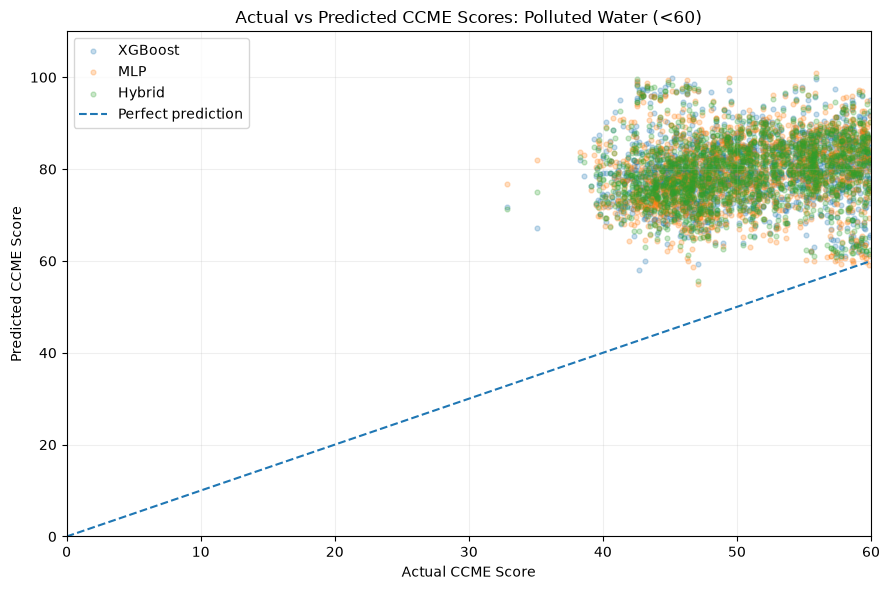

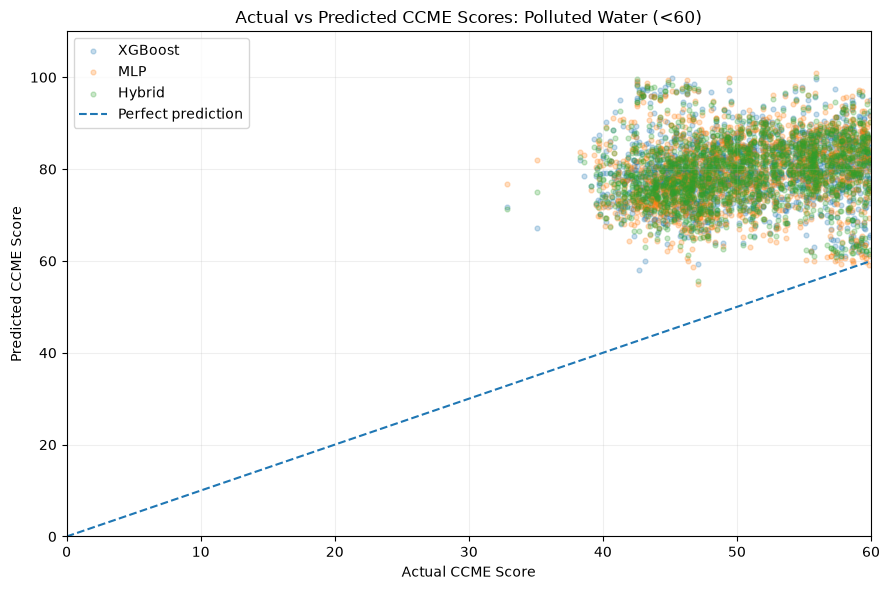

In [18]:
# 13. Actual vs predicted values for polluted water

plt.figure(figsize=(9, 6))

for model_name, pred_col in prediction_columns.items():
    plt.scatter(
        polluted_df["y_true"],
        polluted_df[pred_col],
        alpha=0.25,
        s=12,
        label=model_name
    )

plt.plot(
    [0, 60],
    [0, 60],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual CCME Score")
plt.ylabel("Predicted CCME Score")
plt.title("Actual vs Predicted CCME Scores: Polluted Water (<60)")
plt.xlim(0, 60)
plt.ylim(0, 110)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# 14. Inspect the secondary time-based split

print("split values:")
print(dataset["split"].value_counts(dropna=False))

print("\nsplit_time values:")
print(dataset["split_time"].value_counts(dropna=False))

print("\nYear range by split_time:")
display(
    dataset.groupby("split_time")["year"]
    .agg(["min", "max", "count"])
)

split values:
split
train    181747
test      51973
val       26054
Name: count, dtype: int64

split_time values:
split_time
train    185094
test      53181
val       21499
Name: count, dtype: int64

Year range by split_time:


,min,max,count
split_time,,,
test,2018,2023,53181
train,2000,2015,185094
val,2016,2017,21499


In [20]:
# 15. Inspect existing prediction and model artifacts

print("Available result files:")

for folder in [RESULTS, DL_RESULTS]:
    print(f"\n{folder.relative_to(ROOT)}")

    for file in sorted(folder.glob("*")):
        if file.is_file():
            print(" ", file.name)

Available result files:

results
  .DS_Store
  ablation_validation.csv
  ablations.csv
  final_results.csv
  hybrid_val_preds.csv
  predictions_hybrid.csv
  test_predictions.csv
  training_config.json
  tuning_results.csv
  validation_metrics.csv
  validation_predictions.csv
  year_split_results.csv

results/dl
  .gitkeep
  ccme_band_error_analysis.csv
  country_error_analysis.csv
  experiments_dl.csv
  mlp_config.json
  mlp_history.csv
  paired_rmse_differences.csv
  polluted_water_error_analysis.csv
  predictions_mlp.csv
  predictions_mlp_val.csv
  station_bootstrap_ci.csv
  validation_metrics.csv


In [21]:
# 16. Inspect existing year-based evaluation results

year_results_path = RESULTS / "year_split_results.csv"

year_results = pd.read_csv(year_results_path)

print("Year-based results shape:", year_results.shape)

print("\nAvailable columns:")
print(year_results.columns.tolist())

print("\nYear-based evaluation results:")
display(year_results.head(20))

print("\nData types:")
print(year_results.dtypes)

Year-based results shape: (4, 5)

Available columns:
['model', 'year-split test MAE', 'RMSE', 'R2', 'station-split test R2']

Year-based evaluation results:


,model,year-split test MAE,RMSE,R2,station-split test R2
0,Mean baseline,9.101037,10.692974,-0.337669,-0.000675
1,Ridge,6.738191,8.786197,0.096863,0.204501
2,Random Forest,5.595667,8.309886,0.192129,0.277774
3,XGBoost,5.448798,8.046572,0.242516,0.293304



Data types:
model                        str
year-split test MAE      float64
RMSE                     float64
R2                       float64
station-split test R2    float64
dtype: object


In [22]:
# 17. Find existing time-based split implementation

for file_path in [
    ROOT / "src/train.py",
    ROOT / "src/train_dl.py",
    ROOT / "src/dl_data.py",
    ROOT / "src/features.py"
]:
    print(f"\n{'=' * 60}")
    print(file_path.name)
    print("=" * 60)

    source = file_path.read_text()

    for line_number, line in enumerate(source.splitlines(), start=1):
        if any(
            keyword in line.lower()
            for keyword in ["split_time", "split_column", "train_test_split"]
        ):
            print(f"{line_number}: {line}")


train.py

train_dl.py

dl_data.py
31:     if split_col not in ("split", "split_time"):
32:         raise ValueError("split_col must be 'split' or 'split_time'")
102:     print("Station overlap (split_time, reported only):",
103:           load_dl_data(split_col="split_time")["station_overlap"])

features.py
36:     "site_id", "date", "split", "split_time", "row_id",
139:     split_col="split" is the main (by station) split, "split_time" the secondary (by year).
142:     assert split_col in ("split", "split_time"), "split_col must be 'split' or 'split_time'"


In [23]:
# 18. Inspect existing data-loading implementation

import inspect
from src.dl_data import load_dl_data
from src.features import get_xy, make_features

print("LOAD_DL_DATA FUNCTION")
print(inspect.getsource(load_dl_data))

print("\nGET_XY FUNCTION")
print(inspect.getsource(get_xy))

print("\nMAKE_FEATURES FUNCTION")
print(inspect.getsource(make_features))

LOAD_DL_DATA FUNCTION
def load_dl_data(
    path="data/processed/final_dataset.csv",
    split_col="split",
):
    """Return preprocessed NumPy arrays, feature names, station ids and row ids.

    Extra keys (not model inputs):
      groups_train / groups_val / groups_test  station id (site_id) of each row, for GroupKFold
      row_id_train / row_id_val / row_id_test  row number in final_dataset.csv, for joining predictions
      station_overlap  dict with the computed number of stations shared between splits
    """

    if split_col not in ("split", "split_time"):
        raise ValueError("split_col must be 'split' or 'split_time'")

    # 1. Load dataset and reuse Phase 1 feature engineering
    df = load_final_dataset(path)
    df = make_features(df)

    # 2. Reuse existing train, validation and test splits
    X_train, y_train, X_val, y_val, X_test, y_test = get_xy(
        df, split_col=split_col
    )

    # 3. Station ids and row ids of every split (same order as X and y)
    

In [24]:
# 19. Inspect complete time-based data loader

import inspect

source = inspect.getsource(load_dl_data)

print(source)

def load_dl_data(
    path="data/processed/final_dataset.csv",
    split_col="split",
):
    """Return preprocessed NumPy arrays, feature names, station ids and row ids.

    Extra keys (not model inputs):
      groups_train / groups_val / groups_test  station id (site_id) of each row, for GroupKFold
      row_id_train / row_id_val / row_id_test  row number in final_dataset.csv, for joining predictions
      station_overlap  dict with the computed number of stations shared between splits
    """

    if split_col not in ("split", "split_time"):
        raise ValueError("split_col must be 'split' or 'split_time'")

    # 1. Load dataset and reuse Phase 1 feature engineering
    df = load_final_dataset(path)
    df = make_features(df)

    # 2. Reuse existing train, validation and test splits
    X_train, y_train, X_val, y_val, X_test, y_test = get_xy(
        df, split_col=split_col
    )

    # 3. Station ids and row ids of every split (same order as X and y)
    parts = {k: df[df[spli

In [25]:
# Cell 19: Inspect the existing MLP training implementation

from pathlib import Path

train_dl_path = ROOT / "src" / "train_dl.py"

print(train_dl_path.read_text())

"""
src/train_dl.py
Train and tune the Phase 2 MLP (PyTorch) on the same data, splits and inputs as Phase 1.

Rules (same as Phase 1):
  * every setting is chosen on VALIDATION RMSE only;
  * the test set is never scored here. Test predictions are only saved to disk so that
    the one-time evaluation (src/evaluate_dl.py) can score them once.

Regularisation switches (dropout, weight decay, early stopping, batch norm) are read from
src/regularisation.py, so ablations can change them one at a time.

Run from the project root:
    python -m src.train_dl                 # full tuning (default 12 random trials + the default setting)
    python -m src.train_dl --trials 4 --epochs 20   # quick smoke test

Outputs (results/dl/):
    experiments_dl.csv         every trial: settings, validation MAE / RMSE / R2, best epoch, time
    mlp_config.json            chosen settings and data description
    mlp_history.csv            train / validation loss per epoch of the chosen model
    predictions_

In [26]:
# Cell 20: Locate functions and classes in train_dl.py

source_lines = train_dl_path.read_text().splitlines()

print(f"Total lines: {len(source_lines)}\n")

for i, line in enumerate(source_lines, start=1):
    if line.startswith(("def ", "class ")) or line.startswith("    def "):
        print(f"Line {i}: {line.strip()}")

Total lines: 227

Line 51: def make_mlp(d_in, widths=(128, 64), dropout=0.2, batch_norm=False):
Line 69: def regression_metrics(y_true, y_pred):
Line 78: def predict(model, X, y_mean, y_std, batch=8192):
Line 88: def train_one(data, cfg, max_epochs=60, verbose=False):
Line 133: def default_cfg():
Line 146: def random_cfgs(n, seed=SEED):
Line 168: def main():


In [27]:
# Cell 21: Inspect MLP architecture and training functions

print("===== MLP ARCHITECTURE =====")
print("\n".join(source_lines[50:68]))

print("\n===== PREDICTION FUNCTION =====")
print("\n".join(source_lines[77:87]))

print("\n===== TRAINING FUNCTION =====")
print("\n".join(source_lines[87:132]))

print("\n===== DEFAULT CONFIGURATION =====")
print("\n".join(source_lines[132:145]))

===== MLP ARCHITECTURE =====
def make_mlp(d_in, widths=(128, 64), dropout=0.2, batch_norm=False):
    """Small MLP for a table: [Linear -> (BatchNorm) -> ReLU -> Dropout] x depth -> Linear(1).

    The last layer has one neuron and no activation, because the score is a plain number.
    """
    layers, d = [], d_in
    for w in widths:
        layers.append(nn.Linear(d, w))
        if batch_norm:
            layers.append(nn.BatchNorm1d(w))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = w
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)



===== PREDICTION FUNCTION =====
def predict(model, X, y_mean, y_std, batch=8192):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32)
        out.append(model(xb).squeeze(1).numpy())
    return np.concatenate(out) * y_std + y_mean


# ------------------------------------------------

In [28]:
# Cell 22: Display the complete MLP training function

print("\n".join(source_lines[87:132]))

def train_one(data, cfg, max_epochs=60, verbose=False):
    """Train one MLP. Early stopping and model choice use validation loss only."""
    set_seed(SEED)
    y_mean, y_std = float(data["y_train"].mean()), float(data["y_train"].std())

    # The target is standardised for stable training; predictions are converted back.
    train = dict(data)
    train["y_train"] = (data["y_train"] - y_mean) / y_std
    loader = make_train_loader(train, batch_size=cfg["batch_size"], seed=SEED)

    model = make_mlp(data["X_train"].shape[1], cfg["widths"], cfg["dropout"], cfg["batch_norm"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.HuberLoss(delta=1.0) if cfg["loss"] == "huber" else nn.MSELoss()

    Xv = torch.as_tensor(data["X_val"], dtype=torch.float32)
    yv_std = torch.as_tensor((data["y_val"] - y_mean) / y_std, dtype=torch.float32)

    best_val, best_state, best_epoch, bad = float("inf"), None, 0, 0
    history = []
    for

In [29]:
# Cell 23: Inspect the training loop and early stopping

print("\n".join(source_lines[103:132]))


    best_val, best_state, best_epoch, bad = float("inf"), None, 0, 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb).squeeze(1), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            n += len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = float(nn.functional.mse_loss(model(Xv).squeeze(1), yv_std))
        history.append({"epoch": epoch, "train_loss": total / n, "val_mse_std": val_loss})
        if verbose:
            print(f"  epoch {epoch:3d} train {total / n:.4f} val {val_loss:.4f}")
        if val_loss < best_val - 1e-5:
            best_val, best_state, best_epoch, bad = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad += 1
            if reg.USE_EARLY_STOPPING and bad >= reg.EARLY_STOPPING_PATIENCE:
       

In [31]:
# Cell 24: Import MLP configuration and inspect regularisation settings

from src.train_dl import default_cfg

print("===== DEFAULT MLP CONFIGURATION =====")
print(default_cfg())

print("\n===== REGULARISATION SETTINGS =====")
print((ROOT / "src" / "regularisation.py").read_text())

===== DEFAULT MLP CONFIGURATION =====
{'widths': (128, 64), 'dropout': 0.2, 'weight_decay': 0.0001, 'batch_norm': False, 'lr': 0.001, 'loss': 'mse', 'batch_size': 512}

===== REGULARISATION SETTINGS =====

"""
Regularisation configuration for Phase 2 Deep Learning.
Settings can be changed individually for ablation experiments.
"""

# Dropout
USE_DROPOUT = True
DROPOUT_RATE = 0.2

# Weight decay
USE_WEIGHT_DECAY = True
WEIGHT_DECAY = 1e-4

# Early stopping
USE_EARLY_STOPPING = True
EARLY_STOPPING_PATIENCE = 10

# Batch normalisation
USE_BATCH_NORM = False



In [32]:
# Cell 25: Load temporal split data

from src.dl_data import load_dl_data

time_data = load_dl_data(split_col="split_time")

print("Temporal split loaded successfully.\n")

for key, value in time_data.items():
    if isinstance(value, np.ndarray):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key}: {value}")

Temporal split loaded successfully.

X_train: shape=(185094, 30), dtype=float32
y_train: shape=(185094,), dtype=float32
X_val: shape=(21499, 30), dtype=float32
y_val: shape=(21499,), dtype=float32
X_test: shape=(53181, 30), dtype=float32
y_test: shape=(53181,), dtype=float32
feature_names: ['num__dissolved_oxygen_mg_l', 'num__ph', 'num__temperature_c', 'num__month_sin', 'num__month_cos', 'num__do_sat_pct', 'num__do_x_temp', 'num__dissolved_oxygen_mg_l_site_prev_mean', 'num__ph_site_prev_mean', 'num__temperature_c_site_prev_mean', 'num__site_prev_n', 'num__days_since_prev', 'num__missingindicator_dissolved_oxygen_mg_l', 'num__missingindicator_ph', 'num__missingindicator_temperature_c', 'num__missingindicator_do_sat_pct', 'num__missingindicator_do_x_temp', 'num__missingindicator_dissolved_oxygen_mg_l_site_prev_mean', 'num__missingindicator_ph_site_prev_mean', 'num__missingindicator_temperature_c_site_prev_mean', 'num__missingindicator_days_since_prev', 'cat__waterbody_type_Canal', 'cat__

In [33]:
# Cell 26: Verify temporal split data integrity

print("===== ARRAY VALIDATION =====")

for split in ["train", "val", "test"]:
    X = time_data[f"X_{split}"]
    y = time_data[f"y_{split}"]
    groups = time_data[f"groups_{split}"]
    row_ids = time_data[f"row_id_{split}"]

    print(f"\n{split.upper()}")
    print("Rows:", len(X))
    print("Feature NaNs:", np.isnan(X).sum())
    print("Target NaNs:", np.isnan(y).sum())
    print("Infinite features:", np.isinf(X).sum())
    print("Unique stations:", len(np.unique(groups)))
    print("Unique row IDs:", len(np.unique(row_ids)))
    print("Target range:", float(y.min()), "to", float(y.max()))

print("\n===== YEAR DISTRIBUTION =====")

dataset = pd.read_csv(ROOT / "data/processed/final_dataset.csv")

for split in ["train", "val", "test"]:
    years = dataset.loc[
        dataset["split_time"] == split, "year"
    ]

    print(
        f"{split.upper()}: "
        f"{years.min()}–{years.max()}, "
        f"{len(years)} rows"
    )

===== ARRAY VALIDATION =====

TRAIN
Rows: 185094
Feature NaNs: 0
Target NaNs: 0
Infinite features: 0
Unique stations: 7290
Unique row IDs: 185094
Target range: 32.82619857788086 to 100.0

VAL
Rows: 21499
Feature NaNs: 0
Target NaNs: 0
Infinite features: 0
Unique stations: 2868
Unique row IDs: 21499
Target range: 39.95819854736328 to 100.0

TEST
Rows: 53181
Feature NaNs: 0
Target NaNs: 0
Infinite features: 0
Unique stations: 4929
Unique row IDs: 53181
Target range: 39.59400177001953 to 100.0

===== YEAR DISTRIBUTION =====
TRAIN: 2000–2015, 185094 rows
VAL: 2016–2017, 21499 rows
TEST: 2018–2023, 53181 rows


In [34]:
# Cell 27: Prepare temporal MLP training data

time_mlp_data = {
    "X_train": time_data["X_train"],
    "y_train": time_data["y_train"],
    "X_val": time_data["X_val"],
    "y_val": time_data["y_val"],
}

print("Temporal MLP training data prepared.")

print("Training features:", time_mlp_data["X_train"].shape)
print("Training targets:", time_mlp_data["y_train"].shape)
print("Validation features:", time_mlp_data["X_val"].shape)
print("Validation targets:", time_mlp_data["y_val"].shape)

Temporal MLP training data prepared.
Training features: (185094, 30)
Training targets: (185094,)
Validation features: (21499, 30)
Validation targets: (21499,)


In [35]:
# Cell 28: Train MLP using the temporal split

from src.train_dl import train_one, default_cfg

time_mlp_cfg = default_cfg()

time_mlp_model, time_y_mean, time_y_std, time_best_epoch, time_mlp_history = train_one(
    time_mlp_data,
    time_mlp_cfg,
    max_epochs=60,
    verbose=True
)

print("\n===== TEMPORAL MLP TRAINING SUMMARY =====")
print("Best epoch:", time_best_epoch)
print("Target mean:", time_y_mean)
print("Target standard deviation:", time_y_std)
print("Configuration:", time_mlp_cfg)

  epoch   1 train 0.7901 val 0.3678
  epoch   2 train 0.7462 val 0.3703
  epoch   3 train 0.7357 val 0.3655
  epoch   4 train 0.7309 val 0.3654
  epoch   5 train 0.7258 val 0.3697
  epoch   6 train 0.7208 val 0.3641
  epoch   7 train 0.7177 val 0.3645
  epoch   8 train 0.7154 val 0.3611
  epoch   9 train 0.7117 val 0.3573
  epoch  10 train 0.7109 val 0.3585
  epoch  11 train 0.7077 val 0.3618
  epoch  12 train 0.7063 val 0.3647
  epoch  13 train 0.7041 val 0.3602
  epoch  14 train 0.7031 val 0.3684
  epoch  15 train 0.7029 val 0.3645
  epoch  16 train 0.7021 val 0.3602
  epoch  17 train 0.7000 val 0.3567
  epoch  18 train 0.6985 val 0.3613
  epoch  19 train 0.6984 val 0.3642
  epoch  20 train 0.6970 val 0.3584
  epoch  21 train 0.6971 val 0.3578
  epoch  22 train 0.6954 val 0.3635
  epoch  23 train 0.6955 val 0.3549
  epoch  24 train 0.6935 val 0.3600
  epoch  25 train 0.6937 val 0.3564
  epoch  26 train 0.6935 val 0.3619
  epoch  27 train 0.6913 val 0.3600
  epoch  28 train 0.6901 val

In [36]:
# Cell 29: Generate temporal MLP validation predictions

from src.train_dl import predict, regression_metrics

time_mlp_val_pred = predict(
    time_mlp_model,
    time_data["X_val"],
    time_y_mean,
    time_y_std
)

time_mlp_metrics = regression_metrics(
    time_data["y_val"],
    time_mlp_val_pred
)

print("===== TEMPORAL MLP VALIDATION RESULTS =====")
print("MAE:", time_mlp_metrics["mae"])
print("RMSE:", time_mlp_metrics["rmse"])
print("R²:", time_mlp_metrics["r2"])

print("\nPrediction range:")
print("Minimum:", time_mlp_val_pred.min())
print("Maximum:", time_mlp_val_pred.max())

===== TEMPORAL MLP VALIDATION RESULTS =====
MAE: 5.555969715118408
RMSE: 8.145122786521977
R²: 0.316661536693573

Prediction range:
Minimum: 57.103523
Maximum: 105.530464


In [37]:
# Cell 30: Inspect saved XGBoost configuration

import json

with open(ROOT / "results" / "training_config.json") as f:
    xgb_config = json.load(f)

print(json.dumps(xgb_config, indent=2))

{
  "target": "target_ccme_value",
  "split": "split (station-based)",
  "random_state": 42,
  "feature_columns": [
    "dissolved_oxygen_mg_l",
    "ph",
    "temperature_c",
    "month_sin",
    "month_cos",
    "do_sat_pct",
    "do_x_temp",
    "dissolved_oxygen_mg_l_site_prev_mean",
    "ph_site_prev_mean",
    "temperature_c_site_prev_mean",
    "site_prev_n",
    "days_since_prev",
    "waterbody_type",
    "country"
  ],
  "selected_parameters": {
    "Ridge": {
      "alpha": 0.001
    },
    "RandomForestRegressor": {
      "max_depth": 16,
      "min_samples_leaf": 5,
      "n_estimators": 300
    },
    "XGBRegressor": {
      "learning_rate": 0.03,
      "max_depth": 8,
      "n_estimators": 300
    }
  },
  "selection_metric": "validation RMSE",
  "test_used_for_tuning": false
}


In [38]:
# Cell 31: Extract selected XGBoost hyperparameters

print("Available models:")
print(list(xgb_config["selected_parameters"].keys()))

print("\n===== XGBOOST PARAMETERS =====")

for model_name, params in xgb_config["selected_parameters"].items():
    if "xgb" in model_name.lower() or "boost" in model_name.lower():
        print("Model:", model_name)
        print(json.dumps(params, indent=2))

Available models:
['Ridge', 'RandomForestRegressor', 'XGBRegressor']

===== XGBOOST PARAMETERS =====
Model: XGBRegressor
{
  "learning_rate": 0.03,
  "max_depth": 8,
  "n_estimators": 300
}


In [39]:
# Cell 32: Inspect Phase 1 XGBoost implementation

train_source = (ROOT / "src" / "train.py").read_text().splitlines()

for i, line in enumerate(train_source):
    if "XGBRegressor" in line:
        start = max(0, i - 5)
        end = min(len(train_source), i + 20)
        print("\n".join(
            f"{j + 1}: {train_source[j]}"
            for j in range(start, end)
        ))

158:     joblib.dump(best_rf, MODEL_DIR / "random_forest.joblib")
159: 
160:     # 4. XGBoost: one setting changes at a time.
161:     print("\n[4/4] Tuning XGBoost...")
162:     try:
163:         from xgboost import XGBRegressor
164:     except ImportError as exc:
165:         raise ImportError(
166:             "XGBoost is required. Install it with: pip install xgboost"
167:         ) from exc
168: 
169:     xgb_settings = (
170:         # depth sweep
171:         [{"n_estimators": 300, "max_depth": d, "learning_rate": 0.05} for d in [4, 6, 8, 10]]
172:         # learning-rate sweep
173:         + [{"n_estimators": 300, "max_depth": 8, "learning_rate": lr} for lr in [0.03, 0.1]]
174:         # more trees
175:         + [{"n_estimators": 600, "max_depth": 8, "learning_rate": 0.05}]
176:     )
177: 
178:     best_xgb = None
179:     best_xgb_rmse = float("inf")
180:     for params in xgb_settings:
181:         print("Trying XGBoost:", params)
182:         model = make_pipeline(
178:   

In [40]:
# Cell 33: Inspect XGBoost model construction and fitting

print("\n".join(
    f"{i + 1}: {train_source[i]}"
    for i in range(178, 215)
))

179:     best_xgb_rmse = float("inf")
180:     for params in xgb_settings:
181:         print("Trying XGBoost:", params)
182:         model = make_pipeline(
183:             XGBRegressor(
184:                 **params,
185:                 objective="reg:squarederror",
186:                 subsample=0.8,
187:                 colsample_bytree=0.8,
188:                 reg_lambda=1.0,
189:                 random_state=RANDOM_STATE,
190:                 n_jobs=-1,
191:                 tree_method="hist",
192:                 verbosity=0,
193:             ),
194:             scale=False,
195:         )
196:         metrics = evaluate_validation(model, X_train, y_train, X_val, y_val)
197:         index = log_trial(trials, "XGBRegressor", params, metrics)
198:         print("Validation:", metrics)
199:         if metrics["rmse"] < best_xgb_rmse:
200:             best_xgb, best_xgb_rmse = model, metrics["rmse"]
201:             winners["XGBRegressor"] = index
202:     joblib.dump(best_xgb, MO

In [42]:
# Cell 34: Train XGBoost on already-preprocessed temporal features

from xgboost import XGBRegressor

time_xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.03,
    objective="reg:squarederror",
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=1,
    tree_method="hist",
    verbosity=0
)

time_xgb_model.fit(
    time_data["X_train"],
    time_data["y_train"]
)

print("Temporal XGBoost training completed.")

Temporal XGBoost training completed.


In [44]:
# Cell 35: Evaluate temporal XGBoost and MLP on validation data

from src.train_dl import regression_metrics, predict
import pandas as pd

# XGBoost validation predictions
time_xgb_val_pred = time_xgb_model.predict(
    time_data["X_val"]
)

# MLP validation predictions
time_mlp_val_pred = predict(
    time_mlp_model,
    time_data["X_val"],
    time_y_mean,
    time_y_std
)

# Compare both models
time_val_results = []

for model_name, predictions in [
    ("XGBoost", time_xgb_val_pred),
    ("MLP", time_mlp_val_pred)
]:
    metrics = regression_metrics(
        time_data["y_val"],
        predictions
    )

    time_val_results.append({
        "Model": model_name,
        **metrics
    })

time_val_metrics = pd.DataFrame(time_val_results)

display(time_val_metrics)

print("Temporal validation comparison completed.")

,Model,mae,rmse,r2
0,XGBoost,5.461627,8.126680,0.319753
1,MLP,5.555970,8.145123,0.316662


Temporal validation comparison completed.


In [45]:
# Cell 36: Select the best temporal hybrid blend using validation data

import numpy as np
import pandas as pd
from src.train_dl import regression_metrics

y_val = time_data["y_val"]

blend_results = []

# Test XGBoost weights from 0% to 100%
for xgb_weight in np.arange(0, 1.01, 0.05):
    mlp_weight = 1 - xgb_weight

    blend_pred = (
        xgb_weight * time_xgb_val_pred
        + mlp_weight * time_mlp_val_pred
    )

    metrics = regression_metrics(y_val, blend_pred)

    blend_results.append({
        "xgb_weight": round(float(xgb_weight), 2),
        "mlp_weight": round(float(mlp_weight), 2),
        **metrics
    })

blend_results_df = pd.DataFrame(blend_results)

# Select the blend with the lowest validation RMSE
best_blend = blend_results_df.loc[
    blend_results_df["rmse"].idxmin()
]

best_time_xgb_weight = float(best_blend["xgb_weight"])
best_time_mlp_weight = float(best_blend["mlp_weight"])

print("Best temporal blend:")
display(best_blend.to_frame().T)

print(
    f"Selected weights: XGBoost={best_time_xgb_weight:.2f}, "
    f"MLP={best_time_mlp_weight:.2f}"
)

print("\nAll tested blend weights:")
display(blend_results_df)

Best temporal blend:


,xgb_weight,mlp_weight,mae,rmse,r2
10,0.5,0.5,5.436088,8.02537,0.336607


Selected weights: XGBoost=0.50, MLP=0.50

All tested blend weights:


,xgb_weight,mlp_weight,mae,rmse,r2
0,0.00,1.00,5.555970,8.145123,0.316661
1,0.05,0.95,5.538927,8.123337,0.320312
2,0.10,0.90,5.522780,8.103697,0.323595
3,0.15,0.85,5.507531,8.086219,0.326509
4,0.20,0.80,5.493375,8.070917,0.329056
5,0.25,0.75,5.480198,8.057803,0.331234
6,0.30,0.70,5.468202,8.046888,0.333045
7,0.35,0.65,5.457549,8.038181,0.334488
8,0.40,0.60,5.448764,8.031689,0.335562
9,0.45,0.55,5.441612,8.027418,0.336269


In [46]:
# Cell 37: Evaluate prediction clipping on temporal validation data

from src.hybrid import clip_predictions
from src.train_dl import regression_metrics

time_hybrid_val_pred = (
    best_time_xgb_weight * time_xgb_val_pred
    + best_time_mlp_weight * time_mlp_val_pred
)

models_to_check = {
    "XGBoost": time_xgb_val_pred,
    "MLP": time_mlp_val_pred,
    "Hybrid": time_hybrid_val_pred
}

clipping_results = []

for model_name, raw_pred in models_to_check.items():

    clipped_pred = clip_predictions(raw_pred, lower=0, upper=100)

    raw_metrics = regression_metrics(
        time_data["y_val"], raw_pred
    )

    clipped_metrics = regression_metrics(
        time_data["y_val"], clipped_pred
    )

    clipping_results.append({
        "Model": model_name,
        "Raw_MAE": raw_metrics["mae"],
        "Clipped_MAE": clipped_metrics["mae"],
        "Raw_RMSE": raw_metrics["rmse"],
        "Clipped_RMSE": clipped_metrics["rmse"],
        "Raw_R2": raw_metrics["r2"],
        "Clipped_R2": clipped_metrics["r2"],
        "Raw_out_of_range": int(
            ((raw_pred < 0) | (raw_pred > 100)).sum()
        )
    })

clipping_results_df = pd.DataFrame(clipping_results)

display(clipping_results_df)

,Model,Raw_MAE,Clipped_MAE,Raw_RMSE,Clipped_RMSE,Raw_R2,Clipped_R2,Raw_out_of_range
0,XGBoost,5.461627,5.452081,8.126680,8.125510,0.319753,0.319948,448
1,MLP,5.555970,5.501833,8.145123,8.134559,0.316662,0.318433,1347
2,Hybrid,5.436088,5.421748,8.025370,8.023341,0.336607,0.336943,792


In [47]:
# Cell 38: Generate station-grouped OOF predictions for temporal XGBoost

import numpy as np
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

X_train = time_data["X_train"]
y_train = time_data["y_train"]
groups_train = time_data["groups_train"]

oof_xgb_pred = np.zeros(len(y_train), dtype=np.float32)

gkf = GroupKFold(n_splits=5)

for fold, (train_idx, valid_idx) in enumerate(
    gkf.split(X_train, y_train, groups=groups_train), start=1
):
    fold_model = XGBRegressor(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.03,
        objective="reg:squarederror",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=1,
        tree_method="hist",
        verbosity=0
    )

    fold_model.fit(
        X_train[train_idx],
        y_train[train_idx]
    )

    oof_xgb_pred[valid_idx] = fold_model.predict(
        X_train[valid_idx]
    )

    fold_rmse = np.sqrt(
        np.mean(
            (y_train[valid_idx] - oof_xgb_pred[valid_idx]) ** 2
        )
    )

    print(f"Fold {fold} RMSE: {fold_rmse:.4f}")

assert np.isfinite(oof_xgb_pred).all()

print("\nOOF predictions generated:", len(oof_xgb_pred))
print("OOF prediction range:", oof_xgb_pred.min(), "to", oof_xgb_pred.max())

Fold 1 RMSE: 11.3501
Fold 2 RMSE: 11.7836
Fold 3 RMSE: 11.6060
Fold 4 RMSE: 11.7372
Fold 5 RMSE: 11.9317

OOF predictions generated: 185094
OOF prediction range: 43.978428 to 102.9404


In [48]:
# Cell 39: Prepare residual-learning targets

# Training residuals from station-grouped OOF predictions
time_residual_train = y_train - oof_xgb_pred

# Validation residuals from the XGBoost model trained on all temporal training data
time_residual_val = (
    time_data["y_val"] - time_xgb_val_pred
)

# Prepare data for the residual MLP
time_residual_data = {
    "X_train": time_data["X_train"],
    "y_train": time_residual_train,
    "X_val": time_data["X_val"],
    "y_val": time_residual_val
}

print("Residual target preparation completed.")
print("\nTraining residuals:")
print("Mean:", np.mean(time_residual_train))
print("Standard deviation:", np.std(time_residual_train))
print("Minimum:", np.min(time_residual_train))
print("Maximum:", np.max(time_residual_train))

print("\nValidation residuals:")
print("Mean:", np.mean(time_residual_val))
print("Standard deviation:", np.std(time_residual_val))

assert np.isfinite(time_residual_train).all()
assert np.isfinite(time_residual_val).all()

Residual target preparation completed.

Training residuals:
Mean: 0.035786975
Standard deviation: 11.683301
Minimum: -58.069378
Maximum: 44.79424

Validation residuals:
Mean: 1.0182912
Standard deviation: 8.06263


In [49]:
# Cell 40: Train residual MLP

from src.train_dl import train_one, default_cfg

time_residual_cfg = default_cfg()

(
    time_residual_model,
    time_residual_y_mean,
    time_residual_y_std,
    time_residual_best_epoch,
    time_residual_history
) = train_one(
    time_residual_data,
    time_residual_cfg,
    max_epochs=60,
    verbose=True
)

print("\nResidual MLP training completed.")
print("Best epoch:", time_residual_best_epoch)
print("Residual target mean:", time_residual_y_mean)
print("Residual target standard deviation:", time_residual_y_std)

  epoch   1 train 0.9970 val 0.5099
  epoch   2 train 0.9926 val 0.5057
  epoch   3 train 0.9916 val 0.5037
  epoch   4 train 0.9906 val 0.5063
  epoch   5 train 0.9896 val 0.5120
  epoch   6 train 0.9882 val 0.5131
  epoch   7 train 0.9871 val 0.5110
  epoch   8 train 0.9864 val 0.5179
  epoch   9 train 0.9846 val 0.5101
  epoch  10 train 0.9834 val 0.5228
  epoch  11 train 0.9825 val 0.5075
  epoch  12 train 0.9803 val 0.5117
  epoch  13 train 0.9789 val 0.5124

Residual MLP training completed.
Best epoch: 3
Residual target mean: 0.03578697517514229
Residual target standard deviation: 11.683300971984863


In [50]:
# Cell 41: Evaluate residual-learning hybrid

from src.train_dl import predict, regression_metrics
from src.hybrid import clip_predictions

# Predict residual corrections
time_residual_correction = predict(
    time_residual_model,
    time_data["X_val"],
    time_residual_y_mean,
    time_residual_y_std
)

# Add corrections to full-training XGBoost predictions
time_residual_hybrid_pred = (
    time_xgb_val_pred + time_residual_correction
)

# Existing 50:50 blend
time_blend_pred = (
    0.50 * time_xgb_val_pred
    + 0.50 * time_mlp_val_pred
)

# Compare all approaches
comparison_models = {
    "XGBoost": time_xgb_val_pred,
    "MLP": time_mlp_val_pred,
    "Blending (50:50)": time_blend_pred,
    "Residual Learning": time_residual_hybrid_pred
}

residual_comparison = []

for model_name, raw_pred in comparison_models.items():

    clipped_pred = clip_predictions(
        raw_pred,
        lower=0,
        upper=100
    )

    metrics = regression_metrics(
        time_data["y_val"],
        clipped_pred
    )

    residual_comparison.append({
        "Model": model_name,
        **metrics
    })

residual_comparison_df = pd.DataFrame(residual_comparison)

display(
    residual_comparison_df.sort_values("rmse")
)

print("\nResidual correction diagnostics:")
print("Mean correction:", np.mean(time_residual_correction))
print("Correction standard deviation:", np.std(time_residual_correction))
print("Correction correlation with actual residual:",
      np.corrcoef(time_residual_correction, time_residual_val)[0, 1])

,Model,mae,rmse,r2
2,Blending (50:50),5.421748,8.023341,0.336943
0,XGBoost,5.452081,8.125510,0.319948
1,MLP,5.501833,8.134559,0.318433
3,Residual Learning,5.488022,8.167305,0.312934



Residual correction diagnostics:
Mean correction: 0.3267382
Correction standard deviation: 1.7984394
Correction correlation with actual residual: -0.001256150808791298


In [51]:
# Cell 42: Save selected temporal validation predictions

from pathlib import Path
import pandas as pd
from src.hybrid import clip_predictions

time_hybrid_val_pred = (
    0.50 * time_xgb_val_pred
    + 0.50 * time_mlp_val_pred
)

time_val_export = pd.DataFrame({
    "row_id": time_data["row_id_val"],
    "y_true": time_data["y_val"],
    "xgb_pred": clip_predictions(time_xgb_val_pred, 0, 100),
    "mlp_pred": clip_predictions(time_mlp_val_pred, 0, 100),
    "hybrid_pred": clip_predictions(time_hybrid_val_pred, 0, 100)
})

output_dir = ROOT / "results" / "dl"
output_dir.mkdir(parents=True, exist_ok=True)

time_val_export.to_csv(
    output_dir / "year_split_validation_predictions.csv",
    index=False
)

print("Saved temporal validation predictions.")
print("Rows:", len(time_val_export))
display(time_val_export.head())

Saved temporal validation predictions.
Rows: 21499


,row_id,y_true,xgb_pred,mlp_pred,hybrid_pred
0,207,100.000000,92.990158,92.082047,92.536102
1,2581,100.000000,92.990158,92.082047,92.536102
2,206,93.116699,94.524544,92.475212,93.499878
3,2574,93.116699,94.524544,92.475212,93.499878
4,208,93.116699,96.558380,93.990372,95.274376


In [52]:
# Cell 43: Final temporal test evaluation

from src.hybrid import clip_predictions
from src.train_dl import regression_metrics

# Generate test predictions
time_xgb_test_pred = time_xgb_model.predict(
    time_data["X_test"]
)

time_mlp_test_pred = predict(
    time_mlp_model,
    time_data["X_test"],
    time_y_mean,
    time_y_std
)

# Selected 50:50 blend
time_hybrid_test_pred = (
    0.50 * time_xgb_test_pred
    + 0.50 * time_mlp_test_pred
)

# Apply the validation-selected clipping rule consistently
test_predictions = {
    "XGBoost": clip_predictions(time_xgb_test_pred, 0, 100),
    "MLP": clip_predictions(time_mlp_test_pred, 0, 100),
    "Hybrid": clip_predictions(time_hybrid_test_pred, 0, 100)
}

# Final test metrics
test_results = []

for model_name, predictions in test_predictions.items():
    metrics = regression_metrics(
        time_data["y_test"],
        predictions
    )

    test_results.append({
        "Model": model_name,
        **metrics
    })

year_test_metrics = pd.DataFrame(test_results)

display(year_test_metrics)

# Save final predictions
time_test_export = pd.DataFrame({
    "row_id": time_data["row_id_test"],
    "y_true": time_data["y_test"],
    "xgb_pred": test_predictions["XGBoost"],
    "mlp_pred": test_predictions["MLP"],
    "hybrid_pred": test_predictions["Hybrid"]
})

time_test_export.to_csv(
    output_dir / "year_split_test_predictions.csv",
    index=False
)

year_test_metrics.to_csv(
    output_dir / "year_split_test_metrics.csv",
    index=False
)

print("\nFinal temporal test evaluation completed.")
print("Test rows:", len(time_test_export))
print("Prediction files saved in:", output_dir)

,Model,mae,rmse,r2
0,XGBoost,5.469209,8.060546,0.239883
1,MLP,5.277490,7.865906,0.276149
2,Hybrid,5.300701,7.842071,0.280529



Final temporal test evaluation completed.
Test rows: 53181
Prediction files saved in: /Users/prathapanianusha/water-quality-prediction/results/dl


In [53]:
# Cell 44: Attach country and CCME class to temporal test predictions

import pandas as pd
import numpy as np

dataset = pd.read_csv(
    ROOT / "data" / "processed" / "final_dataset.csv"
)

# Reconstruct the original row IDs
dataset.index.name = "row_id"
metadata = dataset.reset_index()[
    ["row_id", "country", "target_ccme_class"]
]

time_test_analysis = time_test_export.merge(
    metadata,
    on="row_id",
    how="left",
    validate="one_to_one"
)

assert len(time_test_analysis) == len(time_test_export)
assert time_test_analysis["country"].notna().all()
assert time_test_analysis["target_ccme_class"].notna().all()
assert np.allclose(
    time_test_analysis["y_true"],
    dataset.loc[time_test_analysis["row_id"], "target_ccme_value"].to_numpy()
)

print("Temporal test metadata alignment verified.")
print("Rows:", len(time_test_analysis))
print("\nCountries:")
print(time_test_analysis["country"].value_counts())

print("\nCCME classes:")
print(time_test_analysis["target_ccme_class"].value_counts())

Temporal test metadata alignment verified.
Rows: 53181

Countries:
country
England    25527
Ireland    23478
USA         3101
Canada      1075
Name: count, dtype: int64

CCME classes:
target_ccme_class
Excellent    30033
Good         19038
Fair          2912
Marginal      1133
Poor            65
Name: count, dtype: int64


In [54]:
# Cell 45: Country-level temporal test error analysis

country_results = []

for country, group in time_test_analysis.groupby("country"):

    for model_name, pred_col in [
        ("XGBoost", "xgb_pred"),
        ("MLP", "mlp_pred"),
        ("Hybrid", "hybrid_pred")
    ]:

        y_true = group["y_true"].to_numpy()
        y_pred = group[pred_col].to_numpy()

        metrics = regression_metrics(y_true, y_pred)

        country_results.append({
            "Country": country,
            "Model": model_name,
            "Rows": len(group),
            **metrics,
            "Mean_Error": np.mean(y_pred - y_true)
        })

country_test_analysis = pd.DataFrame(country_results)

display(
    country_test_analysis.sort_values(
        ["Country", "rmse"]
    )
)

country_test_analysis.to_csv(
    output_dir / "year_split_country_error_analysis.csv",
    index=False
)

print("Country-level analysis saved.")

,Country,Model,Rows,mae,rmse,r2,Mean_Error
0,Canada,XGBoost,1075,7.308323,11.915212,0.011158,3.108318
2,Canada,Hybrid,1075,7.342028,12.129770,-0.024775,3.824048
1,Canada,MLP,1075,7.606684,12.450263,-0.079644,4.539778
5,England,Hybrid,25527,7.537639,9.835332,0.178609,-2.274752
3,England,XGBoost,25527,7.582083,9.903643,0.167160,-2.514293
4,England,MLP,25527,7.616782,9.981406,0.154030,-2.036503
7,Ireland,MLP,23478,2.954553,4.763691,-0.253030,-0.751798
8,Ireland,Hybrid,23478,3.112627,5.048736,-0.407472,-0.996551
6,Ireland,XGBoost,23478,3.424543,5.661528,-0.769872,-1.372011
11,USA,Hybrid,3101,2.745026,3.792104,0.221183,-1.734478


Country-level analysis saved.


In [55]:
# Cell 46: CCME-class temporal test error analysis

class_results = []

for ccme_class, group in time_test_analysis.groupby("target_ccme_class"):

    for model_name, pred_col in [
        ("XGBoost", "xgb_pred"),
        ("MLP", "mlp_pred"),
        ("Hybrid", "hybrid_pred")
    ]:

        y_true = group["y_true"].to_numpy()
        y_pred = group[pred_col].to_numpy()

        metrics = regression_metrics(y_true, y_pred)

        class_results.append({
            "CCME_Class": ccme_class,
            "Model": model_name,
            "Rows": len(group),
            **metrics,
            "Mean_Error": np.mean(y_pred - y_true)
        })

class_test_analysis = pd.DataFrame(class_results)

display(
    class_test_analysis.sort_values(
        ["CCME_Class", "rmse"]
    )
)

class_test_analysis.to_csv(
    output_dir / "year_split_ccme_class_error_analysis.csv",
    index=False
)

print("CCME-class analysis saved.")

,CCME_Class,Model,Rows,mae,rmse,r2,Mean_Error
1,Excellent,MLP,30033,4.312689,6.233100,0.000000,-4.312689
2,Excellent,Hybrid,30033,4.451455,6.465899,0.000000,-4.451455
0,Excellent,XGBoost,30033,4.681511,6.961306,0.000000,-4.681511
3,Fair,XGBoost,2912,10.541414,12.320776,-7.633618,9.918652
5,Fair,Hybrid,2912,11.060586,12.709625,-8.187179,10.564264
4,Fair,MLP,2912,11.703045,13.295264,-9.053346,11.204607
8,Good,Hybrid,19038,4.469914,5.824528,-1.879213,-0.562263
7,Good,MLP,19038,4.467419,5.836819,-1.891377,-0.252373
6,Good,XGBoost,19038,4.715628,6.110029,-2.168391,-0.890638
9,Marginal,XGBoost,1133,24.024313,25.594891,-21.331526,24.020524


CCME-class analysis saved.


In [56]:
# Cell 47: Analyse predictions for polluted water (CCME < 60)

polluted_test = time_test_analysis[
    time_test_analysis["y_true"] < 60
].copy()

polluted_results = []

for model_name, pred_col in [
    ("XGBoost", "xgb_pred"),
    ("MLP", "mlp_pred"),
    ("Hybrid", "hybrid_pred")
]:

    y_true = polluted_test["y_true"].to_numpy()
    y_pred = polluted_test[pred_col].to_numpy()

    metrics = regression_metrics(y_true, y_pred)

    polluted_results.append({
        "Model": model_name,
        "Rows": len(polluted_test),
        **metrics,
        "Mean_Error": np.mean(y_pred - y_true),
        "Overprediction_Rate": np.mean(y_pred > y_true) * 100,
        "Mean_Prediction": np.mean(y_pred),
        "Mean_Actual": np.mean(y_true)
    })

polluted_test_results = pd.DataFrame(polluted_results)

display(polluted_test_results)

polluted_test_results.to_csv(
    output_dir / "year_split_polluted_water_analysis.csv",
    index=False
)

print("Polluted-water analysis saved.")

,Model,Rows,mae,rmse,r2,Mean_Error,Overprediction_Rate,Mean_Prediction,Mean_Actual
0,XGBoost,766,27.923580,29.362753,-34.445349,27.923580,100.0,80.760728,52.837147
1,MLP,766,29.836005,31.185460,-38.982507,29.836005,100.0,82.673153,52.837147
2,Hybrid,766,28.881384,30.208390,-36.516376,28.881384,100.0,81.718532,52.837147


Polluted-water analysis saved.


In [57]:
theory_path = ROOT / "docs" / "theory_dl.md"

if theory_path.exists():
    print(theory_path.read_text())
else:
    print("theory_dl.md does not exist yet.")

# Theoretical rigor (Phase 2, deep learning)

Sections 4.1 to 4.4 (how the network learns) are written by Priyal. Sections 4.5 to 4.8 (regularisation, bias and variance, trees vs networks, hybrids and out-of-fold predictions) are written by Anusha and added below. Every section uses our real settings: MLP 30 -> 128 -> 64 -> 1, ReLU, MSE, Adam (learning rate 0.001, batch size 512), dropout 0.2, weight decay 1e-4, seed 42.

## 4.1 Neuron, layer and activation

A neuron takes the inputs x, computes a weighted sum plus a bias, then applies an activation:

z = w . x + b,  a = f(z)

A layer is many neurons side by side, so a layer is a matrix multiplication followed by f. Our network has two hidden layers (128 and 64 neurons) and one output neuron.

- **Why we need an activation.** Without f, two layers compute W2(W1 x) = (W2 W1) x, which is still one linear model. Ridge already covers that case (validation R2 0.219). The non-linearity is what lets the network model curves and interactions, 

In [58]:
theory_text = theory_path.read_text()

start = theory_text.find("## 4.5")
if start == -1:
    print("Section 4.5 not found.")
else:
    print(theory_text[start:])

Section 4.5 not found.


In [59]:
anusha_sections = r"""

## 4.5 Regularisation

A neural network can learn the training data too closely, including noise and patterns that do not generalise to unseen observations. Regularisation reduces this risk by discouraging unnecessarily complex solutions.

Our MLP uses three regularisation techniques:

- **Dropout (0.2):** During training, dropout randomly disables 20% of the hidden-layer activations. This prevents the network from relying too heavily on particular neurons and encourages it to learn more robust representations. Dropout is disabled during evaluation.
- **Weight decay (1e-4):** We use L2-style weight regularisation through Adam's weight-decay parameter. It penalises large weights and encourages a simpler model.
- **Early stopping:** Training monitors validation loss. If validation performance does not improve for 10 consecutive epochs, training stops and restores the best-performing model checkpoint. This avoids continuing to fit the training data after generalisation has stopped improving.

Our configuration uses dropout 0.2, weight decay 0.0001 and early-stopping patience 10. Batch normalisation is disabled.

These techniques address different aspects of overfitting: dropout reduces dependence between neurons, weight decay discourages large weights, and early stopping limits unnecessary training.

## 4.6 Bias, variance and overfitting

Bias and variance describe two different sources of prediction error.

- **High bias:** A model is too simple to capture important relationships in the data. It underfits and performs poorly on both training and unseen data.
- **High variance:** A model is too sensitive to its training observations. It may perform very well on training data but poorly on unseen data.
- **Overfitting:** The model learns patterns specific to the training data that do not generalise reliably.

We use separate validation data to monitor generalisation and select model configurations. The final test set is kept separate from model selection.

Our results show why validation and test performance must both be considered. On the temporal split, the selected hybrid achieved validation RMSE of approximately 8.02 and test RMSE of approximately 7.84. This result does not by itself prove that the model has no overfitting; it shows that its performance was maintained on the later-year test period.

We also examined errors by country and CCME water-quality category. This revealed that good overall performance can hide substantial subgroup errors. In particular, all three models overpredicted every polluted-water observation in the temporal test subset (766 observations with actual CCME scores below 60). This is an important limitation that aggregate metrics alone would not reveal.

## 4.7 Why trees often outperform neural networks on tabular data

Neural networks are powerful, but they are not automatically the best choice for structured tabular datasets.

Tree-based models such as XGBoost have several advantages:

- They naturally learn non-linear relationships and interactions between features.
- They can work effectively with mixed patterns in numerical and categorical-derived features.
- They do not require the same neural-network architecture and optimisation choices, such as layer widths, learning rates and regularisation settings.
- They can perform strongly on datasets where useful information is already represented in engineered features.

Our dataset contains structured water-quality measurements, station information, country and waterbody characteristics, and engineered features. XGBoost therefore provides a strong baseline.

On the station-based validation split, XGBoost achieved RMSE 11.2048, compared with 11.2311 for the MLP. The MLP did not outperform XGBoost on this validation comparison.

On the temporal validation split, XGBoost achieved RMSE 8.1267 and the MLP achieved 8.1451. Their performance was close, with XGBoost slightly ahead.

These results support using XGBoost as a strong tabular-data baseline rather than assuming that a neural network must perform better simply because it is a deep-learning model.

## 4.8 Hybrid models and out-of-fold predictions

A hybrid model combines predictions from different model types. The motivation is that models may capture different patterns and their errors may complement one another.

Our project combines XGBoost and an MLP using a weighted blend:

\[
\hat{y}_{hybrid} =
w\hat{y}_{XGB} + (1-w)\hat{y}_{MLP}
\]

The blending weight is selected using validation data only. The selected weight is then applied to the corresponding test predictions.

For the station-based split, the selected blend used 55% XGBoost and 45% MLP. For the temporal split, the selected blend used 50% XGBoost and 50% MLP. The different weights reflect the fact that the two splits represent different generalisation settings.

### Why out-of-fold predictions are necessary

When training a residual-learning hybrid, we first generate out-of-fold (OOF) XGBoost predictions for the training observations.

We divide the training stations into five folds using GroupKFold. For each fold:

1. Train XGBoost on the other four folds.
2. Predict the observations in the held-out fold.
3. Store those predictions in their original row positions.

Every training observation therefore receives a prediction from a model that did not train on that observation.

The residual target is then calculated as:

\[
r_{train} = y_{train} - \hat{y}_{XGB,OOF}
\]

A residual MLP can be trained to predict these residuals. At prediction time, the correction is added to predictions from an XGBoost model fitted on the full training split.

Using in-sample XGBoost predictions to create residual targets would produce overly optimistic residuals because the model has already seen those observations. OOF predictions reduce this leakage risk.

### What we found

We tested both weighted blending and residual learning.

Residual learning was not selected. Its validation residual corrections had very weak correlation with the actual residuals: approximately 0.0877 on the station-based split and approximately -0.0013 on the temporal split. This indicated that the residual MLP was not learning a useful correction signal.

Weighted blending was therefore selected as the final hybrid approach.

On the temporal test split, the hybrid achieved RMSE 7.8421, compared with 8.0605 for XGBoost and 7.8659 for the MLP. The hybrid achieved the best RMSE and R² among the three models, although the MLP achieved the lowest MAE.

The hybrid therefore improved overall temporal test performance, but it did not eliminate the overprediction problem for polluted-water observations. This demonstrates why hybrid models must be evaluated using both overall metrics and subgroup error analysis.
"""

if "## 4.5 Regularisation" in theory_text:
    raise ValueError("Sections 4.5–4.8 already appear to exist. No changes made.")
else:
    theory_path.write_text(
        theory_text.rstrip() + "\n\n" + anusha_sections.strip() + "\n"
    )
    print("Sections 4.5–4.8 appended successfully.")
    print("Updated file:", theory_path)

Sections 4.5–4.8 appended successfully.
Updated file: /Users/prathapanianusha/water-quality-prediction/docs/theory_dl.md


In [60]:
theory_text = theory_path.read_text()

for heading in [
    "## 4.1", "## 4.2", "## 4.3", "## 4.4",
    "## 4.5 Regularisation",
    "## 4.6 Bias, variance and overfitting",
    "## 4.7 Why trees often outperform neural networks on tabular data",
    "## 4.8 Hybrid models and out-of-fold predictions"
]:
    print(f"{'FOUND' if heading in theory_text else 'MISSING'}: {heading}")

print("\nTotal characters:", len(theory_text))

FOUND: ## 4.1
FOUND: ## 4.2
FOUND: ## 4.3
FOUND: ## 4.4
FOUND: ## 4.5 Regularisation
FOUND: ## 4.6 Bias, variance and overfitting
FOUND: ## 4.7 Why trees often outperform neural networks on tabular data
FOUND: ## 4.8 Hybrid models and out-of-fold predictions

Total characters: 12084


In [62]:
# Cell 52: Consolidate evaluation metrics with consistent column names

station_metrics = pd.read_csv(output_dir / "validation_metrics.csv")
temporal_test_metrics = pd.read_csv(output_dir / "year_split_test_metrics.csv")

# Standardise metric column names
station_metrics = station_metrics.rename(columns={
    "MAE": "MAE",
    "RMSE": "RMSE",
    "R2": "R2",
    "mae": "MAE",
    "rmse": "RMSE",
    "r2": "R2"
})

temporal_test_metrics = temporal_test_metrics.rename(columns={
    "MAE": "MAE",
    "RMSE": "RMSE",
    "R2": "R2",
    "mae": "MAE",
    "rmse": "RMSE",
    "r2": "R2"
})

station_metrics["Evaluation"] = "Station-split validation"
temporal_test_metrics["Evaluation"] = "Year-split test"

metrics_dl = pd.concat(
    [station_metrics, temporal_test_metrics],
    ignore_index=True
)

# Keep only the required columns
metrics_dl = metrics_dl[["Model", "MAE", "RMSE", "R2", "Evaluation"]]

metrics_path = output_dir / "metrics_dl.csv"
metrics_dl.to_csv(metrics_path, index=False)

print("Consolidated metrics saved successfully.")
print("Shape:", metrics_dl.shape)
display(metrics_dl)

Consolidated metrics saved successfully.
Shape: (6, 5)


,Model,MAE,RMSE,R2,Evaluation
0,XGBoost,7.729225,11.204831,0.347799,Station-split validation
1,MLP,7.767292,11.231056,0.344743,Station-split validation
2,Hybrid,7.675917,11.141434,0.355159,Station-split validation
3,XGBoost,5.469209,8.060546,0.239883,Year-split test
4,MLP,5.277490,7.865906,0.276149,Year-split test
5,Hybrid,5.300701,7.842071,0.280529,Year-split test


In [63]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else "Working tree is clean.")

print("\nLatest commit:")
log = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(log.stdout)

 M docs/theory_dl.md
 M notebooks/08_dl_evaluation.ipynb
?? results/dl/ccme_band_error_analysis.csv
?? results/dl/country_error_analysis.csv
?? results/dl/metrics_dl.csv
?? results/dl/paired_rmse_differences.csv
?? results/dl/polluted_water_error_analysis.csv
?? results/dl/station_bootstrap_ci.csv
?? results/dl/validation_metrics.csv
?? results/dl/year_split_ccme_class_error_analysis.csv
?? results/dl/year_split_country_error_analysis.csv
?? results/dl/year_split_polluted_water_analysis.csv
?? results/dl/year_split_test_metrics.csv
?? results/dl/year_split_test_predictions.csv
?? results/dl/year_split_validation_predictions.csv


Latest commit:
de82a21 Implement and validate XGBoost MLP hybrid model

